In [1]:
# Imports
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from tensorflow.keras.optimizers import Adam

In [2]:
# paths
train_dir = 'Date_Fruit/train'
val_dir = 'Date_Fruit/test'

# parameters
IMG_SIZE = (200, 200)
BATCH_SIZE = 32

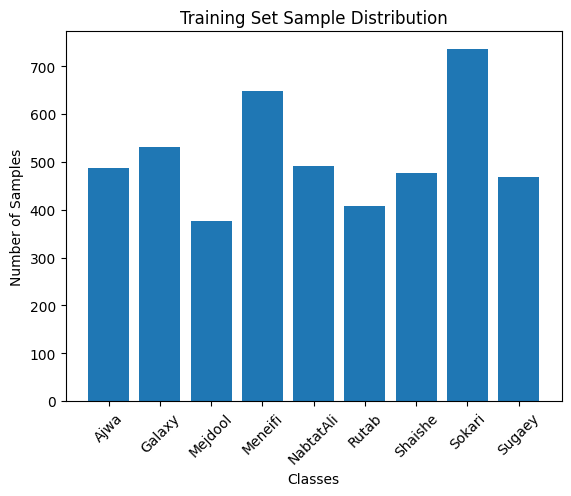

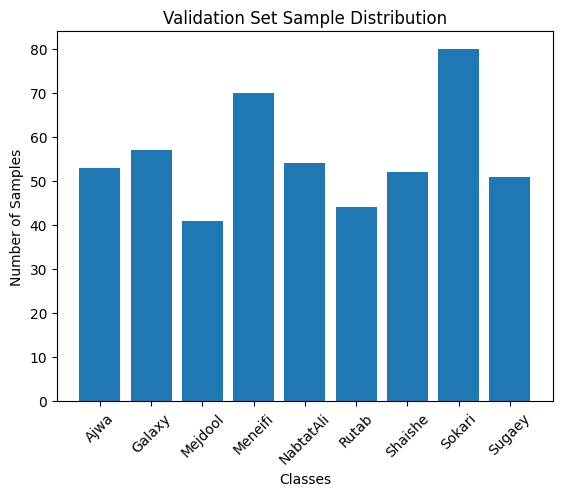

In [3]:
# Data visualization: Count samples per label
def plot_label_distribution(directory, title):
    labels = []
    for subdir in os.listdir(directory):
        path = os.path.join(directory, subdir)
        if os.path.isdir(path):
            labels.append(len(os.listdir(path)))

    plt.bar(os.listdir(directory), labels)
    plt.title(title)
    plt.xlabel('Classes')
    plt.ylabel('Number of Samples')
    plt.xticks(rotation=45)
    plt.show()

# Plot for training set
plot_label_distribution(train_dir, "Training Set Sample Distribution")

# Plot for validation set
plot_label_distribution(val_dir, "Validation Set Sample Distribution")

In [4]:
train_datagen = ImageDataGenerator(rescale=1.0/255)
val_datagen = ImageDataGenerator(rescale=1.0/255)

# data generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True  # Ensure shuffling for training data
)

validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False  # Optional for validation, but generally better as False
)



Found 4624 images belonging to 9 classes.
Found 502 images belonging to 9 classes.


In [5]:
#best for now, incremental learning rate, can achieve high val accuarcy with higer eopchs, no overfitting
model = models.Sequential([
    layers.Conv2D(32, (5, 5), activation='relu', input_shape=(200, 200, 3)), # was 400x400
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'), 
    layers.Dropout(0.2),
    layers.Dense(9, activation='softmax')  
])

model.summary()

D:\anaconda3\envs\CS462\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 196, 196, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 98, 98, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16928)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,333,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,357,065 (16.62 MB)

 Trainable params: 4,357,065 (16.62 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
optimizer = Adam(learning_rate=0.00001) # was 0.00001

model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
history = model.fit(
    train_generator,
    epochs=500,  
    validation_data=validation_generator
)

Epoch 1/500


D:\anaconda3\envs\CS462\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


145/145 ━━━━━━━━━━━━━━━━━━━━ 85s 535ms/step - accuracy: 0.1459 - loss: 2.1729 - val_accuracy: 0.2032 - val_loss: 2.1065
Epoch 2/500
145/145 ━━━━━━━━━━━━━━━━━━━━ 86s 587ms/step - accuracy: 0.2237 - loss: 2.0871 - val_accuracy: 0.3586 - val_loss: 1.9743
Epoch 3/500
145/145 ━━━━━━━━━━━━━━━━━━━━ 87s 592ms/step - accuracy: 0.3433 - loss: 1.9167 - val_accuracy: 0.5159 - val_loss: 1.6772
Epoch 4/500
145/145 ━━━━━━━━━━━━━━━━━━━━ 86s 589ms/step - accuracy: 0.4864 - loss: 1.6119 - val_accuracy: 0.5020 - val_loss: 1.3984
Epoch 5/500
145/145 ━━━━━━━━━━━━━━━━━━━━ 81s 548ms/step - accuracy: 0.5629 - loss: 1.3524 - val_accuracy: 0.6355 - val_loss: 1.1908
Epoch 6/500
145/145 ━━━━━━━━━━━━━━━━━━━━ 62s 422ms/step - accuracy: 0.6044 - loss: 1.2082 - val_accuracy: 0.6454 - val_loss: 1.0847
Epoch 7/500
145/145 ━━━━━━━━━━━━━━━━━━━━ 62s 423ms/step - accuracy: 0.6490 - loss: 1.0863 - val_accuracy: 0.6653 - val_loss: 0.9952
Epoch 8/500
145/145 ━━━━━━━━━━━━━━━━━━━━ 62s 421ms/step - accuracy: 0.6501 - loss: 1.028

KeyboardInterrupt: 

In [8]:
# Evaluate the model
loss, accuracy = model.evaluate(validation_generator)
print(f"Validation Loss: {loss}")
print(f"Validation Accuracy: {accuracy}")

# Plot training history
# Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.show()

# Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Model Loss')
plt.show()

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 160ms/step - accuracy: 0.9386 - loss: 0.1935
Validation Loss: 0.21318848431110382
Validation Accuracy: 0.9342629313468933


NameError: name 'history' is not defined

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step
Classification Report:
              precision    recall  f1-score   support

        Ajwa       1.00      1.00      1.00        53
      Galaxy       0.96      0.88      0.92        57
     Mejdool       0.97      0.93      0.95        41
     Meneifi       0.85      0.94      0.89        70
   NabtatAli       0.98      0.89      0.93        54
       Rutab       0.98      0.91      0.94        44
     Shaishe       1.00      0.96      0.98        52
      Sokari       0.89      0.96      0.92        80
      Sugaey       0.89      0.92      0.90        51

    accuracy                           0.93       502
   macro avg       0.95      0.93      0.94       502
weighted avg       0.94      0.93      0.93       502



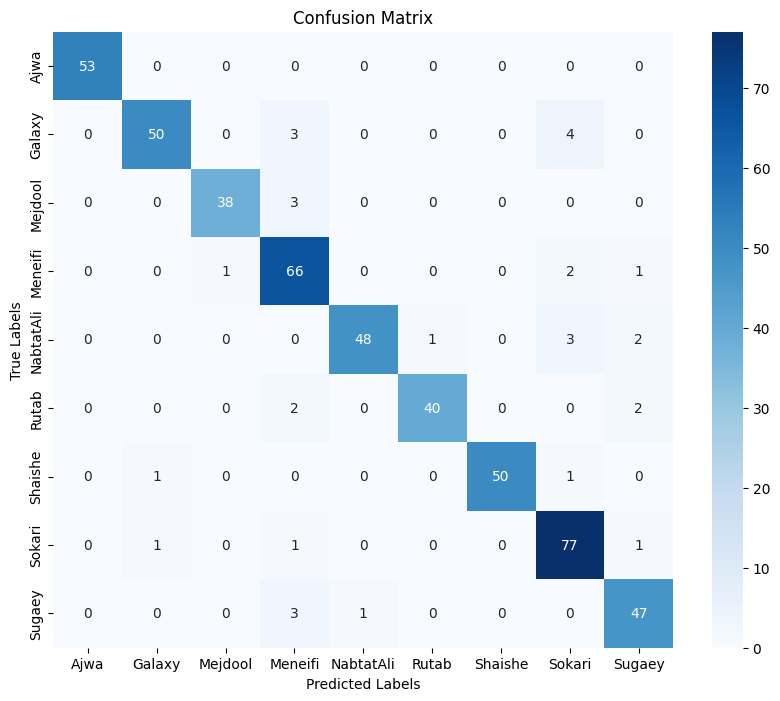

In [9]:
# Confusion Matrix and Classification Report
# Get true labels and predictions
true_labels = validation_generator.classes
class_labels = list(validation_generator.class_indices.keys())

# Predict
predictions = model.predict(validation_generator)
predicted_classes = np.argmax(predictions, axis=1)

# Classification Report
print("Classification Report:")
print(classification_report(true_labels, predicted_classes, target_names=class_labels))

# Confusion Matrix
conf_matrix = confusion_matrix(true_labels, predicted_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()